In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df = pd.read_excel("heart_disease.xlsx", sheet_name="Heart_disease")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


## 2. Basic exploration

In [24]:
df.shape


(908, 13)

In [25]:
df.columns.tolist()


['age',
 'sex',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalch',
 'exang',
 'oldpeak',
 'slope',
 'thal',
 'num']

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB


In [27]:
df.describe()

,age,trestbps,chol,thalch,oldpeak,num
count,908.000000,908.000000,908.000000,908.000000,846.000000,908.000000
mean,53.791850,133.430617,201.484581,135.957048,0.891253,1.008811
std,9.158031,20.401608,112.097949,26.804929,1.093875,1.144436
min,29.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.750000,120.000000,176.750000,118.000000,0.000000,0.000000
50%,54.000000,130.000000,224.000000,138.000000,0.500000,1.000000
75%,60.000000,144.000000,270.000000,156.000000,1.500000,2.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,4.000000


In [28]:
df.isnull().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

In [29]:
df.duplicated().sum()

1

In [30]:
df["num"].value_counts().sort_index()

num
0    399
1    265
2    109
3    107
4     28
Name: count, dtype: int64

The `num` column has values from 0 to 4. In this notebook, 0 means no heart disease and values above 0 mean heart disease is present, so I will use a binary target for the classification model.

## 3. Visualizing the data

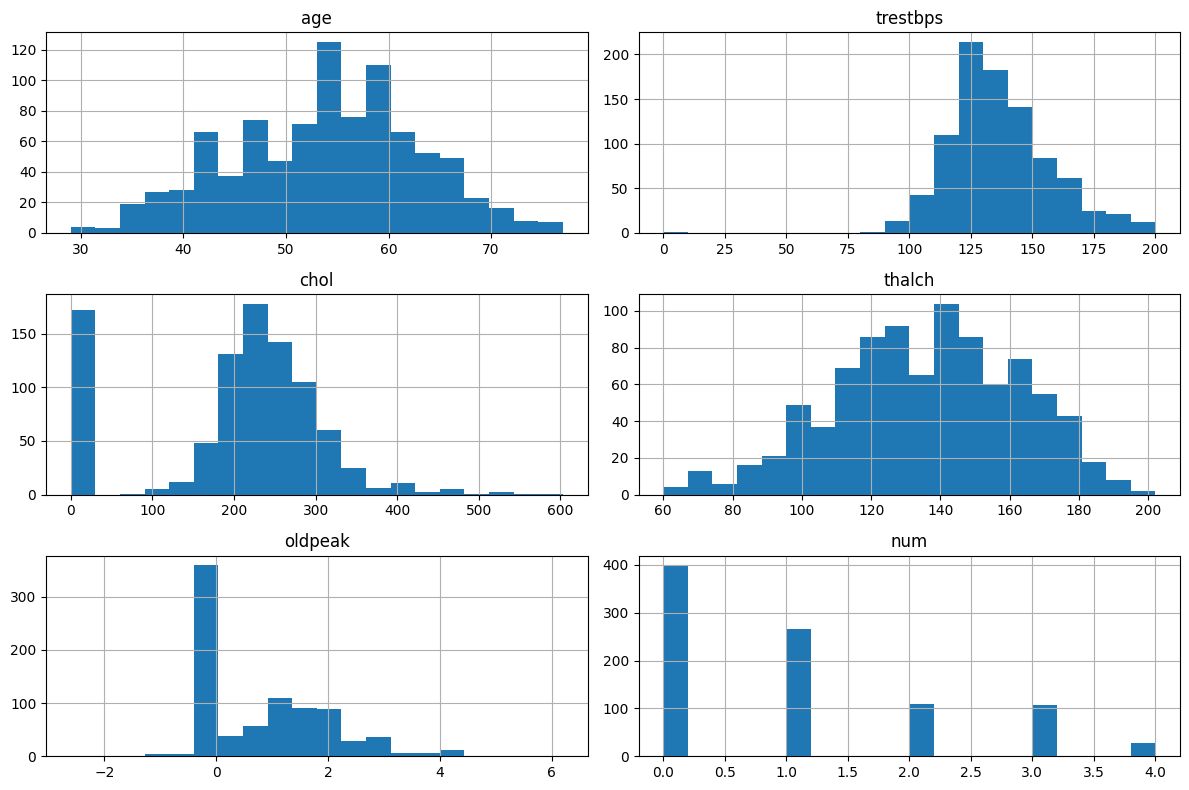

In [31]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
df[num_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

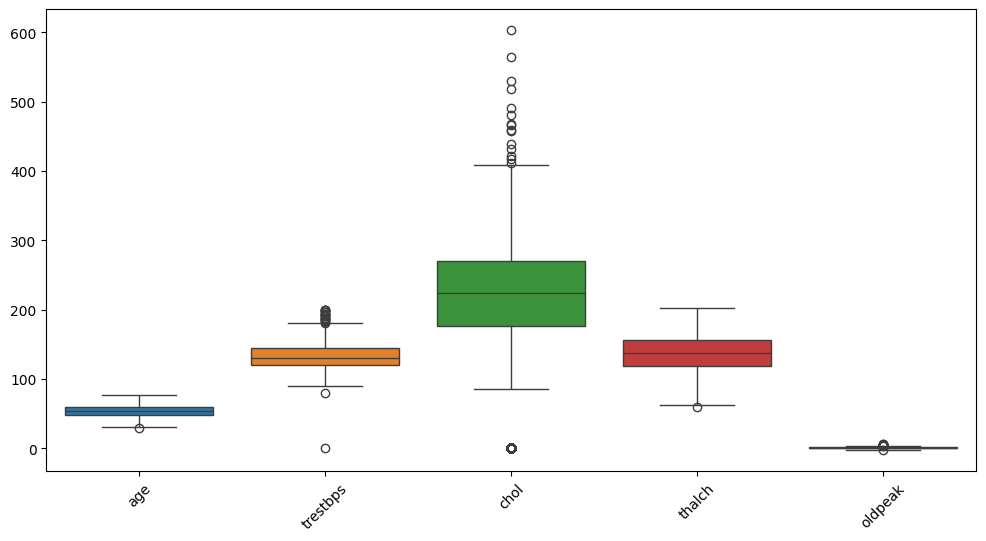

In [32]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[num_cols].drop(columns=["num"], errors="ignore"))
plt.xticks(rotation=45)
plt.show()

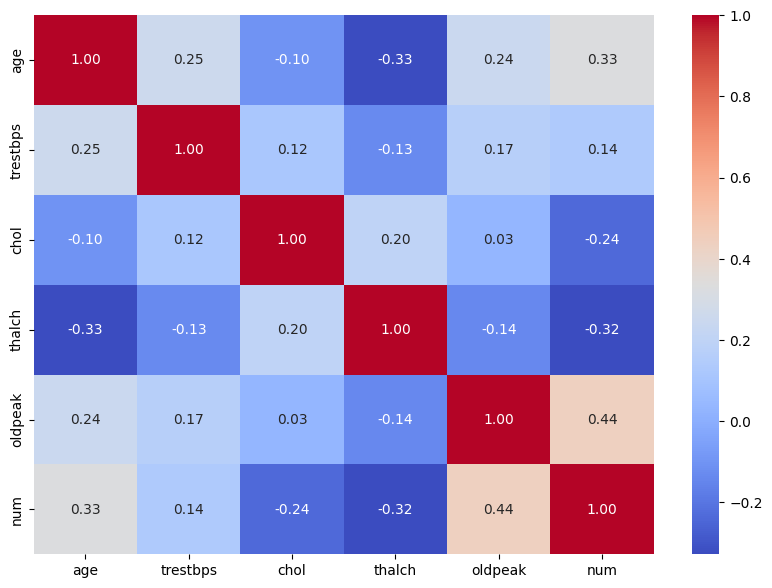

In [33]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [34]:
df["exang"].value_counts(dropna=False)

exang
False    516
True     337
TURE      36
FALSE     19
Name: count, dtype: int64

## 4. Data cleaning

In [35]:
df = df.drop_duplicates().copy()
df["trestbps"] = df["trestbps"].replace(0, np.nan)
df["chol"] = df["chol"].replace(0, np.nan)
df["exang"] = df["exang"].astype(str).str.strip().str.lower()
df["exang"] = df["exang"].replace({"ture": "yes", "true": "yes", "false": "no"})
df["target"] = (df["num"] > 0).astype(int)
df.isnull().sum()

age           0
sex           0
cp            0
trestbps      1
chol        172
fbs           0
restecg       0
thalch        0
exang         0
oldpeak      62
slope         0
thal          0
num           0
target        0
dtype: int64

In [36]:
df[["num", "target"]].head()

,num,target
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [37]:
df["target"].value_counts()

target
1    508
0    399
Name: count, dtype: int64

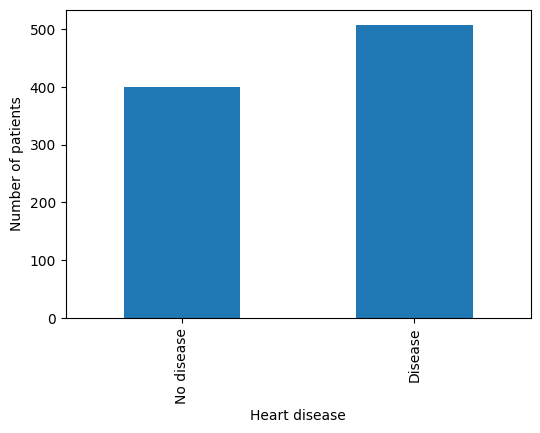

In [38]:
plt.figure(figsize=(6, 4))
df["target"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No disease", "Disease"])
plt.xlabel("Heart disease")
plt.ylabel("Number of patients")
plt.show()

## 5. Feature relationships

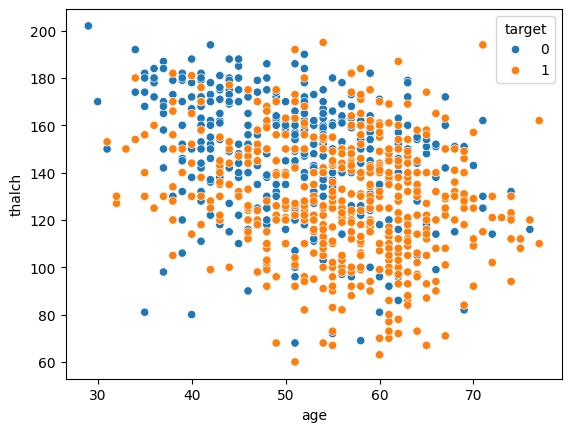

In [39]:
sns.scatterplot(data=df, x="age", y="thalch", hue="target")
plt.show()

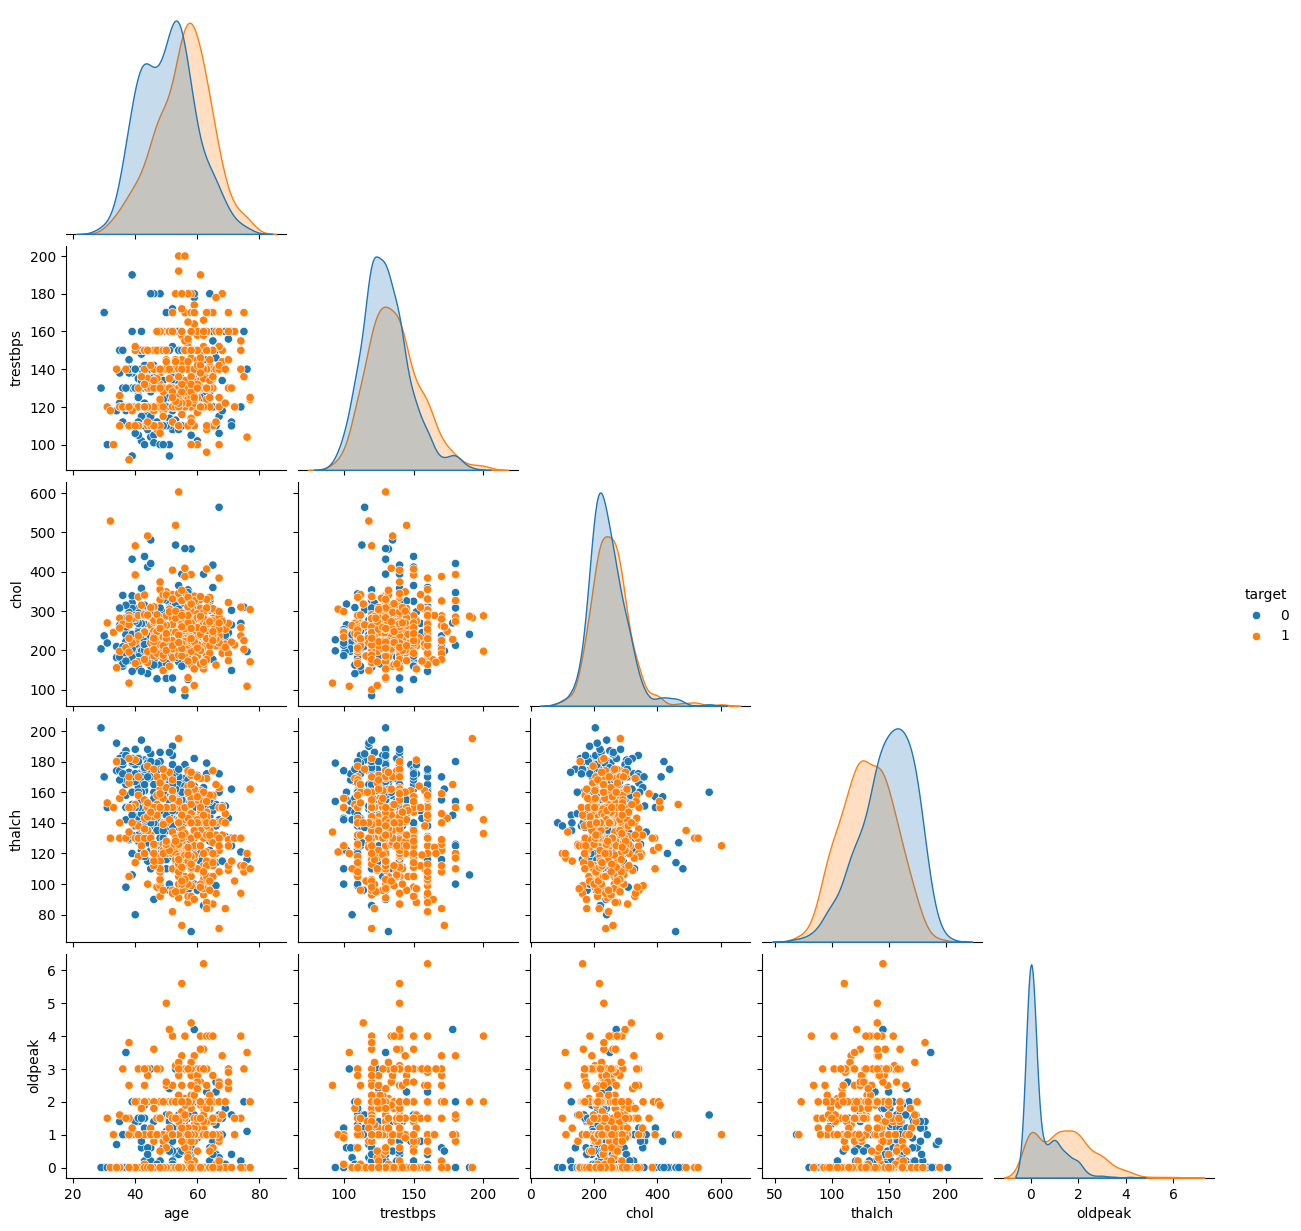

In [40]:
sns.pairplot(
    df[["age", "trestbps", "chol", "thalch", "oldpeak", "target"]].dropna(),
    hue="target",
    corner=True
)
plt.show()

## 6. Prepare the data

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns=["num", "target"])
y = df["target"]

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", num_features)
print("Categorical features:", cat_features)

Numerical features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [42]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 725
Testing rows: 182


## 7. Train a Decision Tree

In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import RocCurveDisplay
from sklearn.tree import plot_tree

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 0.731
Precision: 0.748
Recall: 0.784
F1-score: 0.766
ROC-AUC: 0.723


In [44]:
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], zero_division=0))

              precision    recall  f1-score   support

  No disease       0.71      0.66      0.68        80
     Disease       0.75      0.78      0.77       102

    accuracy                           0.73       182
   macro avg       0.73      0.72      0.72       182
weighted avg       0.73      0.73      0.73       182



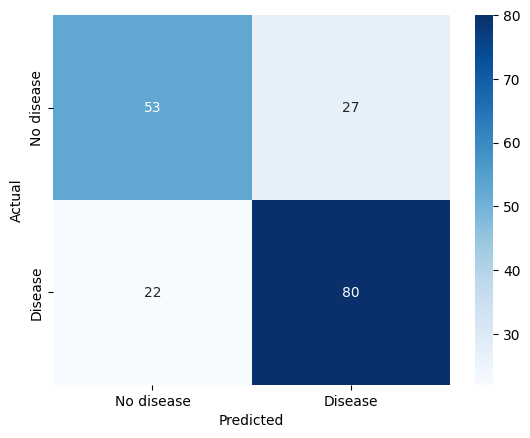

In [45]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

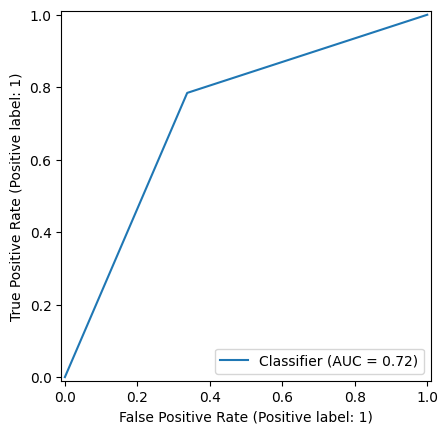

In [46]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.show()

## 8. Hyperparameter tuning

In [47]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_split": [2, 5, 10]
}

grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation F1-score:", round(grid.best_score_, 3))

Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_split': 10}
Best cross-validation F1-score: 0.777


In [48]:
best_model = grid.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 3))
print("Precision:", round(precision_score(y_test, tuned_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, tuned_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, tuned_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 3))

Accuracy: 0.758
Precision: 0.754
Recall: 0.843
F1-score: 0.796
ROC-AUC: 0.768


## 9. Compare the models

In [49]:
results = pd.DataFrame({
    "Model": ["Decision Tree - Default", "Decision Tree - Tuned"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tuned_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, tuned_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, tuned_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, tuned_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, tuned_prob)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree - Default,0.731,0.748,0.784,0.766,0.723
1,Decision Tree - Tuned,0.758,0.754,0.843,0.796,0.768


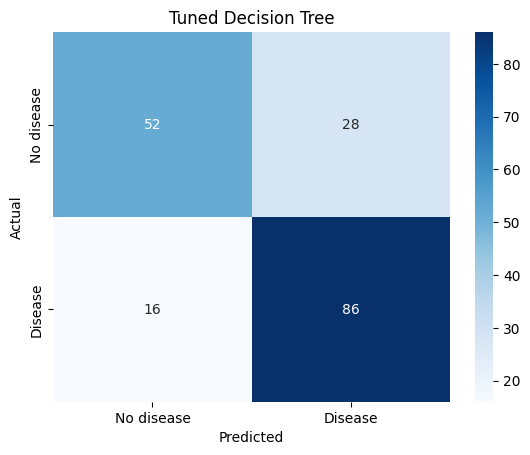

In [50]:
cm = confusion_matrix(y_test, tuned_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Decision Tree")
plt.show()

## 10. Visualize the Decision Tree

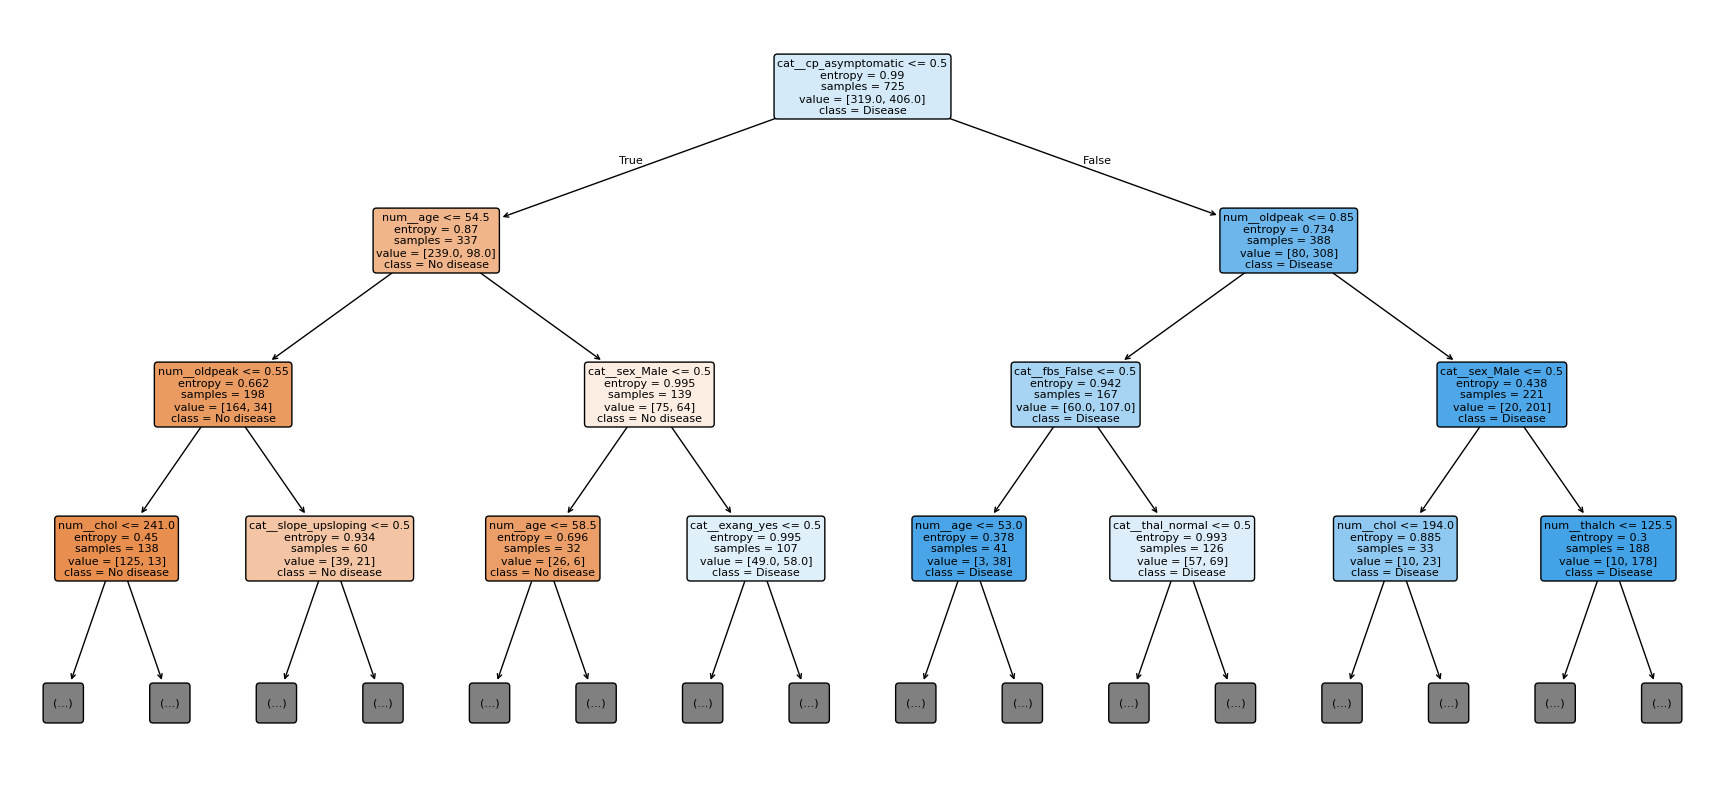

In [51]:
tree_model = best_model.named_steps["classifier"]
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.show()

In [52]:
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.head(10)

,Feature,Importance
7,cat__cp_asymptomatic,0.380687
4,num__oldpeak,0.166342
3,num__thalch,0.093553
0,num__age,0.086301
2,num__chol,0.072787
6,cat__sex_Male,0.057032
11,cat__fbs_False,0.045492
20,cat__slope_upsloping,0.032331
22,cat__thal_normal,0.023294
17,cat__exang_yes,0.018310


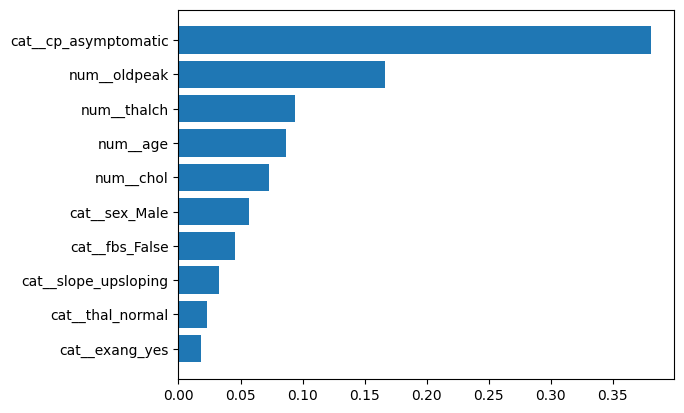

In [53]:
top_features = importance.head(10).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.show()